# 

# Example of the aitlas toolbox in the context of object detection

## Import the required packages

In [ ]:
from aitlas.datasets import SeaDronesSeeDataset
from aitlas.models import FasterRCNN
from aitlas.transforms import Resize
from aitlas.utils import image_loader

## Load the dataset

In [7]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/images/train",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/annotations/instances_train.json",
    "selection": "all",
}
dataset = SeaDronesSeeDataset(dataset_config)
print(len(dataset))

8930


## Show images from the dataset

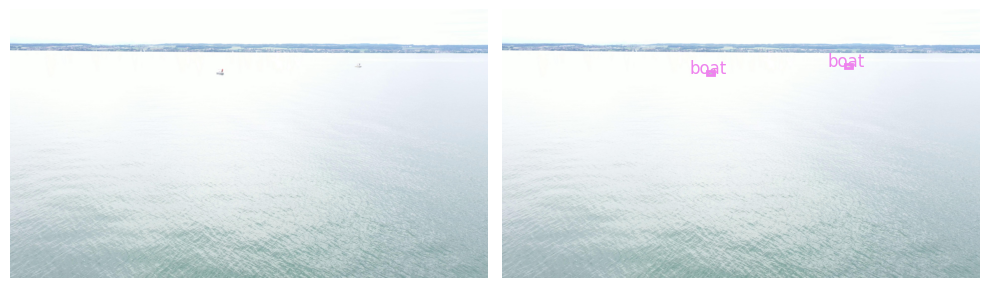

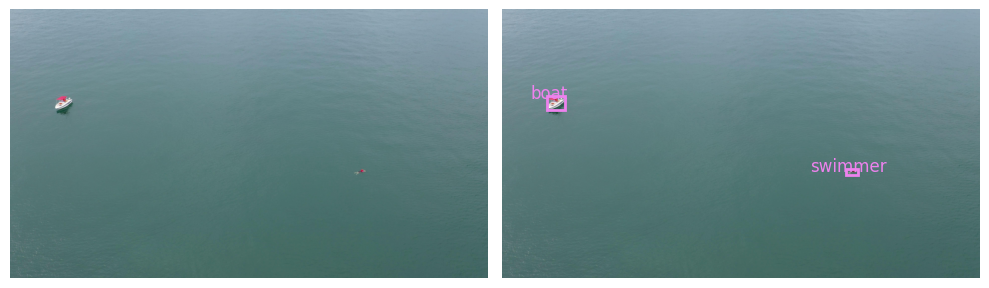

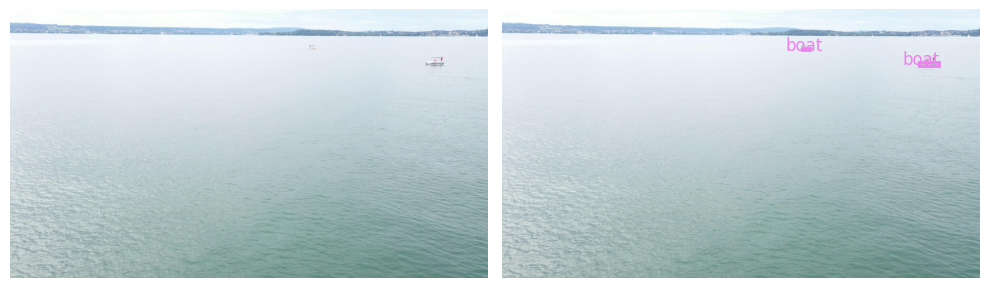

In [12]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(50)

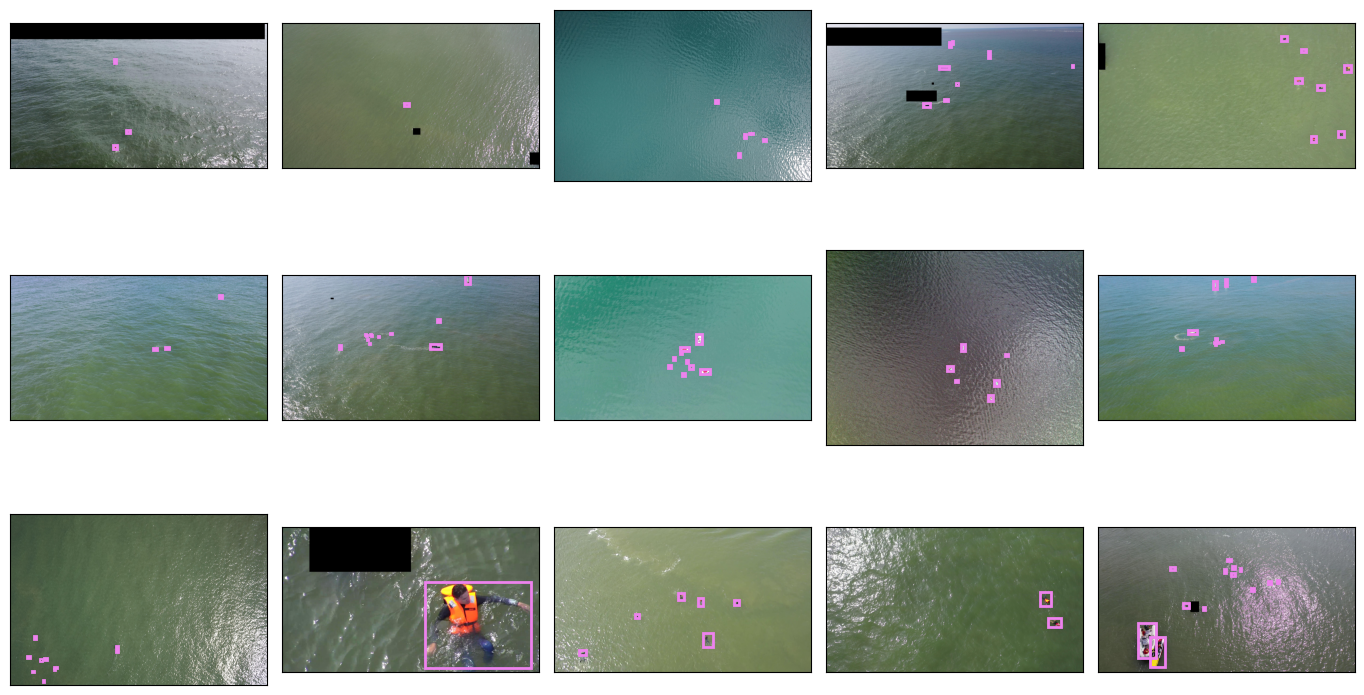

In [4]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [5]:
dataset.data_distribution_table()

,Label,Count
0,swimmer,37096
1,boat,13022
2,buoy,4389
3,jetski,2330
4,life_saving_appliances,923


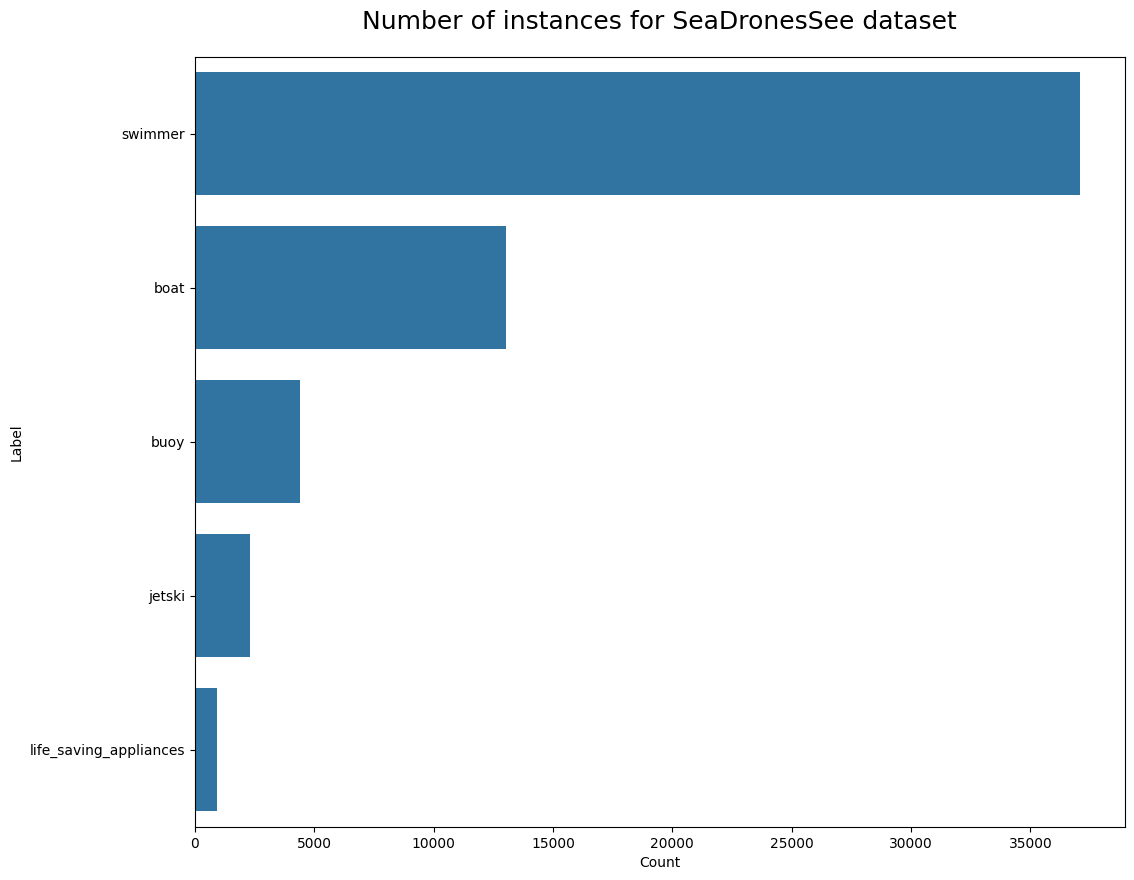

In [6]:
fig = dataset.data_distribution_barchart()

## Load training data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/images/train",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/annotations/instances_train.json",
    "selection": "/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SeaDronesSeeDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 8930


## Setup and create the model for training

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/SeaDronesSee/"
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Training 

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-22 12:34:26,863 INFO Starting training.
training: 100%|██████████| 1117/1117 [15:34<00:00,  1.19it/s]
2025-07-22 12:50:02,395 INFO epoch: 1, time: 935, loss:  0.40774
testing on train set: 100%|██████████| 1117/1117 [19:17<00:00,  1.04s/it]
2025-07-22 13:09:49,512 INFO map:0.4556555449962616, map_50:0.7819985151290894, map_75:0.4675089418888092, map_small:0.44518613815307617, map_medium:0.6648222804069519, map_large:0.7442302107810974, mar_1:0.3733408451080322, mar_10:0.5269975662231445, mar_100:0.5278542637825012, mar_small:0.5201406478881836, mar_medium:0.7285773754119873, mar_large:0.7760899066925049, map_per_class:tensor(0.3006), tensor(0.6984), tensor(0.5081), tensor(0.2256), tensor(0.5455), mar_100_per_class:tensor(0.3889), tensor(0.7523), tensor(0.5845), tensor(0.2804), tensor(0.6332), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32), tensor(5, dtype=torch.int32)
training: 100%|██████████| 1117

## Evaluate the model

In [9]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/images/val",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/annotations/instances_val.json",
    "selection": "/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SeaDronesSeeDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/SeaDronesSee/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 1547


2025-07-23 06:25:15,139 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SeaDronesSee/checkpoint.pth.tar
2025-07-23 06:25:16,171 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SeaDronesSee/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 194/194 [01:35<00:00,  2.02it/s]


[{'map': 0.4390149414539337,
  'map_50': 0.7554035782814026,
  'map_75': 0.444273978471756,
  'map_small': 0.44048744440078735,
  'map_medium': 0.5784403681755066,
  'map_large': 0.3571828305721283,
  'mar_1': 0.33017078042030334,
  'mar_10': 0.5049871206283569,
  'mar_100': 0.5053319931030273,
  'mar_small': 0.5083619356155396,
  'mar_medium': 0.6535430550575256,
  'mar_large': 0.3820512890815735,
  'map_per_class': [tensor(0.2902),
   tensor(0.6658),
   tensor(0.5438),
   tensor(0.2082),
   tensor(0.4871)],
  'mar_100_per_class': [tensor(0.3934),
   tensor(0.7262),
   tensor(0.6241),
   tensor(0.2318),
   tensor(0.5512)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32)]}]

## Predictions

2025-07-23 06:28:10,390 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SeaDronesSee/checkpoint.pth.tar
2025-07-23 06:28:11,536 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SeaDronesSee/checkpoint.pth.tar at epoch 11


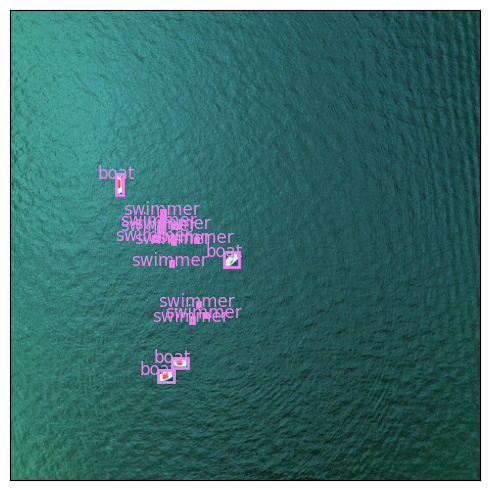

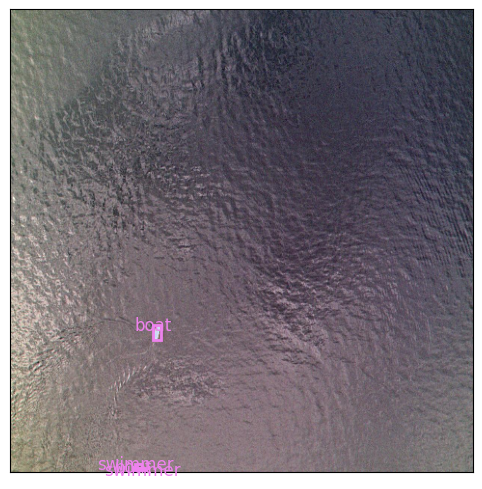

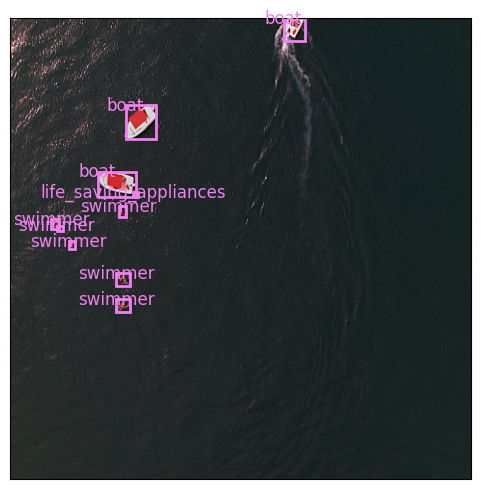

In [11]:
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/SeaDronesSee/checkpoint.pth.tar"
labels = ["ignored","swimmer", "boat",  "jetski", "life_saving_appliances", "buoy"]
transform = Resize()
model.load_model(model_path)

image = image_loader("/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/images/test/46.jpg")
fig = model.detect_objects(image, labels, transform)

image = image_loader("/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/images/test/210.jpg")
fig = model.detect_objects(image, labels, transform)

image = image_loader("/home/dragik/data/FAIR_EO/SeaDronesSee/Compressed Version/images/test/347.jpg")
fig = model.detect_objects(image, labels, transform)